In [2]:
!pip install itables

   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
    --------------------------------------- 0.0/1.6 MB 330.3 kB/s eta 0:00:05
   - -------------------------------------- 0.0/1.6 MB 393.8 kB/s eta 0:00:04
   -- ------------------------------------- 0.1/1.6 MB 590.8 kB/s eta 0:00:03
   ----- ---------------------------------- 0.2/1.6 MB 1.1 MB/s eta 0:00:02
   -------- ------------------------------- 0.3/1.6 MB 1.2 MB/s eta 0:00:02
   ------------ --------------------------- 0.5/1.6 MB 1.7 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.6 MB 2.9 MB/s eta 0:00:01
   --------------------------------- ------ 1.3/1.6 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 1.6/1.6 MB 4.0 MB/s eta 0:00:00



[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)
import numpy as np
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np
import plotly.graph_objects as go

In [12]:
!pwd

/c/Users/rotem/master/nlp/NLPFinalProject


In [14]:
TRAJ_DIR = Path("data/artifacts/recall/rotemab_15shot_top10")

parts = []
for f in TRAJ_DIR.glob("*.parquet"):
    d = pd.read_parquet(f, columns=["id", "step", "correct"])
    step = d["step"].iloc[0]
    parts.append(d[["id", "correct"]].rename(columns={"correct": step}).set_index("id"))

traj = pd.concat(parts, axis=1).sort_index(axis=1).reset_index()
traj.to_csv("15_shot_top_10_trajectory.csv", index= False)
traj.shape

(1452, 14)

In [36]:
df_last_ckpt = pd.read_parquet("C:/Users/rotem/master/nlp/NLPFinalProject/data/artifacts/recall/rotemab_15shot_top10/recall_step658032_15shot_recallonly_top10pct.parquet")

In [37]:
df_last_ckpt

id    step  num_shots  correct  excluded  \
0     6416076  658032         15    False     False   
1      809091  658032         15    False     False   
2       54966  658032         15    False     False   
3     4381377  658032         15     True     False   
4     1030164  658032         15    False     False   
...       ...     ...        ...      ...       ...   
1447  4165948  658032         15     True     False   
1448  2617063  658032         15     True      True   
1449   471864  658032         15     True     False   
1450  2965573  658032         15    False     False   
1451   802449  658032         15     True     False   

                                                 prompt  \
0     The genre of South by Java Head is World War I...   
1     The genre of South by Java Head is World War I...   
2     The genre of South by Java Head is World War I...   
3     The genre of South by Java Head is World War I...   
4     The occupation of Michael Lynton is chief exec...   
...                                                 ...   
1447  The occupation of Michael Lynton is chief exec...   
1448  The occupation of Michael Lynton is chief exec...   
1449  The occupation of Michael Lynton is chief exec...   
1450  The occupation of Michael Lynton is chief exec...   
1451  The occupation of Michael Lynton is chief exec...   

                                             generation  
0                                    'Punk' - Punk rock  
1                                     'The Art of Love'  
2      the subject of the book 'Carl Linnaeus: The M...  
3                  the composer of 'The Sound of Music'  
4                         Camillo Benso, Duke of Cavour  
...                                                 ...  
1447                                          Amsterdam  
1448                                              Celje  
1449                                          New Delhi  
1450                                           Ramallah  
1451                                        Baton Rouge  

[1452 rows x 7 columns]

In [15]:
df = traj
steps = df.columns[1:]
arr = df[steps].to_numpy(dtype=bool)
ever_learned = arr.any(axis=1)
df['ever_learned'] = ever_learned
df["never_forgotten"] = [row[row.argmax():].all() if row.any() else False for row in arr]
df["forgetting_events"] = ((arr[:, :-1]) & (~arr[:, 1:])).sum(axis=1)
first_true = np.argmax(arr, axis=1)
df["first_learning_step"] = np.where(ever_learned, np.array(steps)[first_true], np.nan)

def map_to_category(row):
    if row["never_forgotten"]:
        return "Never forgotten"
    if row[658032]:
        return "Retained"
    if row['ever_learned']:
        return 'forgotten'
    return 'Never learned'

df["category"] = df.apply(map_to_category, axis=1)
print(len(df[df['ever_learned']]))

880


In [16]:
from datasets import load_dataset
ds = load_dataset("dhgottesman/popqa-kas")
qa = ds["train"].to_pandas()

In [34]:
qa['shared_chunks']

Loading ITables v2.9.1 from the init_notebook_mode cell... (need help?)
🔒ⓘshared_chunks
[]
[]
[]
[9159492]
"[4658248, 2626714]"
[9382137]
"[753849, 7961338, 6892509, 4828335]"
"[5447465, 5491245]"
[3497081]


In [17]:
fact_properties = qa[['id', 'prop', 'subject_num_chunks', 'answer_num_chunks', 'num_shared_chunks']]
df = df.merge(fact_properties, on='id', how='inner')
df.to_csv("15_shot_top_10_trajectory_with_fact_properites.csv", index=False)
df

id  50000  100000  150000  200000  250000  300000  350000  400000  \
0     6416076  False   False   False   False   False   False   False   False   
1      809091  False   False   False   False   False   False   False   False   
2       54966  False   False   False   False   False   False   False   False   
3     4381377  False   False   False   False   False   False   False    True   
4     1030164  False   False   False   False   False   False   False   False   
...       ...    ...     ...     ...     ...     ...     ...     ...     ...   
1447  4165948  False    True    True   False    True    True    True    True   
1448  2617063   True    True    True    True   False    True    True    True   
1449   471864  False   False   False   False   False   False    True   False   
1450  2965573  False    True   False   False   False   False   False   False   
1451   802449  False   False    True    True   False   False   False   False   

      450000  ...  658032  ever_learned  never_forgotten  forgetting_events  \
0      False  ...   False         False            False                  0   
1      False  ...   False         False            False                  0   
2      False  ...   False         False            False                  0   
3      False  ...    True          True            False                  1   
4      False  ...   False         False            False                  0   
...      ...  ...     ...           ...              ...                ...   
1447    True  ...    True          True            False                  1   
1448   False  ...    True          True            False                  2   
1449   False  ...    True          True            False                  1   
1450   False  ...   False          True            False                  1   
1451   False  ...    True          True            False                  2   

      first_learning_step       category            prop subject_num_chunks  \
0                     NaN  Never learned      occupation               6047   
1                     NaN  Never learned      occupation               4523   
2                     NaN  Never learned      occupation               5003   
3                  400000       Retained      occupation               1037   
4                     NaN  Never learned  place of birth                430   
...                   ...            ...             ...                ...   
1447               100000       Retained         capital             124221   
1448                50000       Retained         capital                 45   
1449               350000       Retained         capital              19175   
1450               100000      forgotten         capital               2046   
1451               150000       Retained         capital              28890   

     answer_num_chunks num_shared_chunks  
0                 4952                61  
1                 7550               113  
2                 7802                48  
3                 9592                75  
4                12699               152  
...                ...               ...  
1447             26494             11413  
1448               549                43  
1449             13134              2727  
1450             24068               520  
1451              4220              2200  

[1452 rows x 23 columns]

In [18]:
learned = df[df['ever_learned']]
learned

id  50000  100000  150000  200000  250000  300000  350000  400000  \
3     4381377  False   False   False   False   False   False   False    True   
6     2065688   True   False   False   False   False   False    True    True   
7     6292892  False   False   False    True   False   False    True    True   
8     2260300  False   False   False   False   False   False   False   False   
13     237675   True   False   False   False   False   False   False   False   
...       ...    ...     ...     ...     ...     ...     ...     ...     ...   
1447  4165948  False    True    True   False    True    True    True    True   
1448  2617063   True    True    True    True   False    True    True    True   
1449   471864  False   False   False   False   False   False    True   False   
1450  2965573  False    True   False   False   False   False   False   False   
1451   802449  False   False    True    True   False   False   False   False   

      450000  ...  658032  ever_learned  never_forgotten  forgetting_events  \
3      False  ...    True          True            False                  1   
6       True  ...   False          True            False                  2   
7       True  ...    True          True            False                  1   
8      False  ...    True          True             True                  0   
13     False  ...    True          True            False                  2   
...      ...  ...     ...           ...              ...                ...   
1447    True  ...    True          True            False                  1   
1448   False  ...    True          True            False                  2   
1449   False  ...    True          True            False                  1   
1450   False  ...   False          True            False                  1   
1451   False  ...    True          True            False                  2   

      first_learning_step         category            prop subject_num_chunks  \
3                  400000         Retained      occupation               1037   
6                   50000        forgotten  place of birth               5207   
7                  200000         Retained  place of birth                432   
8                  658032  Never forgotten  place of birth                659   
13                  50000         Retained           genre               1686   
...                   ...              ...             ...                ...   
1447               100000         Retained         capital             124221   
1448                50000         Retained         capital                 45   
1449               350000         Retained         capital              19175   
1450               100000        forgotten         capital               2046   
1451               150000         Retained         capital              28890   

     answer_num_chunks num_shared_chunks  
3                 9592                75  
6                 1687              1291  
7               230316               166  
8                59389                43  
13                 862                90  
...                ...               ...  
1447             26494             11413  
1448               549                43  
1449             13134              2727  
1450             24068               520  
1451              4220              2200  

[880 rows x 23 columns]

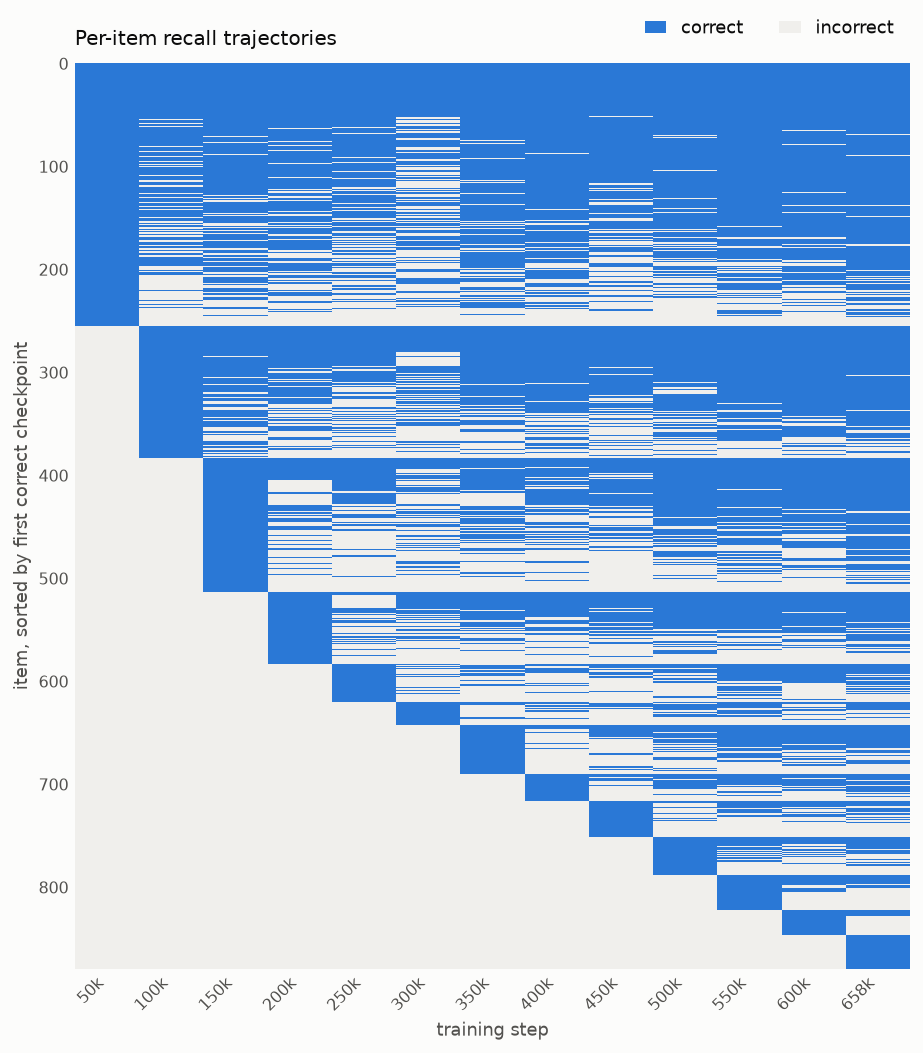

In [19]:
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"

plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

M = learned[steps].to_numpy()      # (2294, 14) bool — ever-correct items
Mall = traj[steps].to_numpy()      # (14109, 14) bool — everything
first = np.argmax(M, axis=1)      # index of first correct checkpoint
tick_lab = [f"{s // 1000}k" for s in steps]
kfmt = lambda v, p: f"{v / 1000:.0f}k"
pfmt = lambda v, p: f"{v:.0%}"
order = np.lexsort((-M.sum(1), first))
fig, ax = plt.subplots(figsize=(7.2, 8.2))
ax.imshow(M[order], aspect="auto", interpolation="nearest",
          cmap=ListedColormap([NEUTRAL, BLUE]))
ax.set_xticks(range(len(steps)), tick_lab, rotation=45, ha="right")
ax.set_xlabel("training step")
ax.set_ylabel("item, sorted by first correct checkpoint")
ax.set_title("Per-item recall trajectories", loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(handles=[Patch(facecolor=BLUE, label="correct"),
                   Patch(facecolor=NEUTRAL, label="incorrect")],
          loc="lower right", bbox_to_anchor=(1, 1.01), ncol=2, handlelength=1.2)
fig.tight_layout()

Text(0.5, 0, 'Training step')

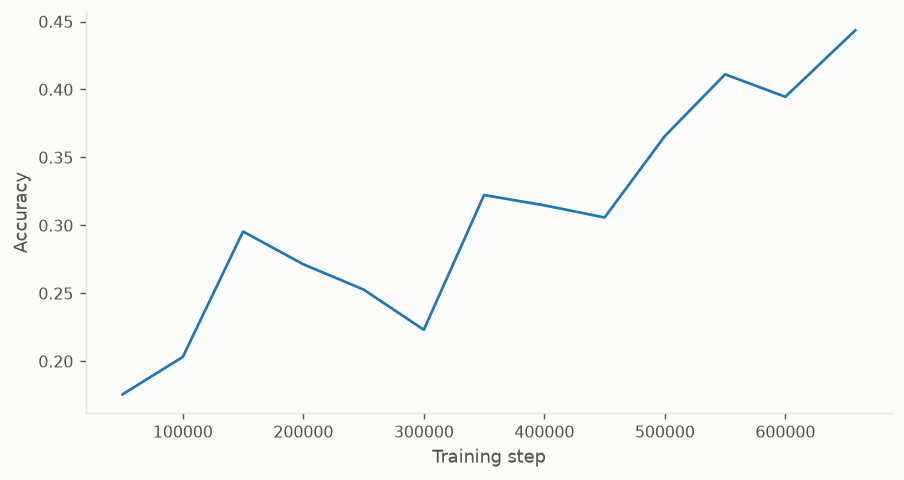

In [21]:
accuracy = arr.mean(axis=0)

plt.figure(figsize=(8,4))
plt.plot(steps, accuracy)
plt.ylabel("Accuracy")
plt.xlabel("Training step")

<Axes: xlabel='forgetting_events'>

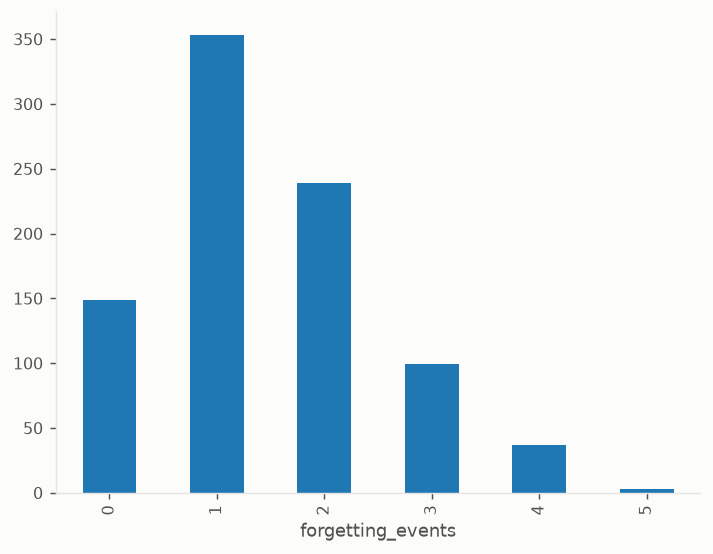

In [22]:
learned['forgetting_events'].value_counts().sort_index().plot.bar()

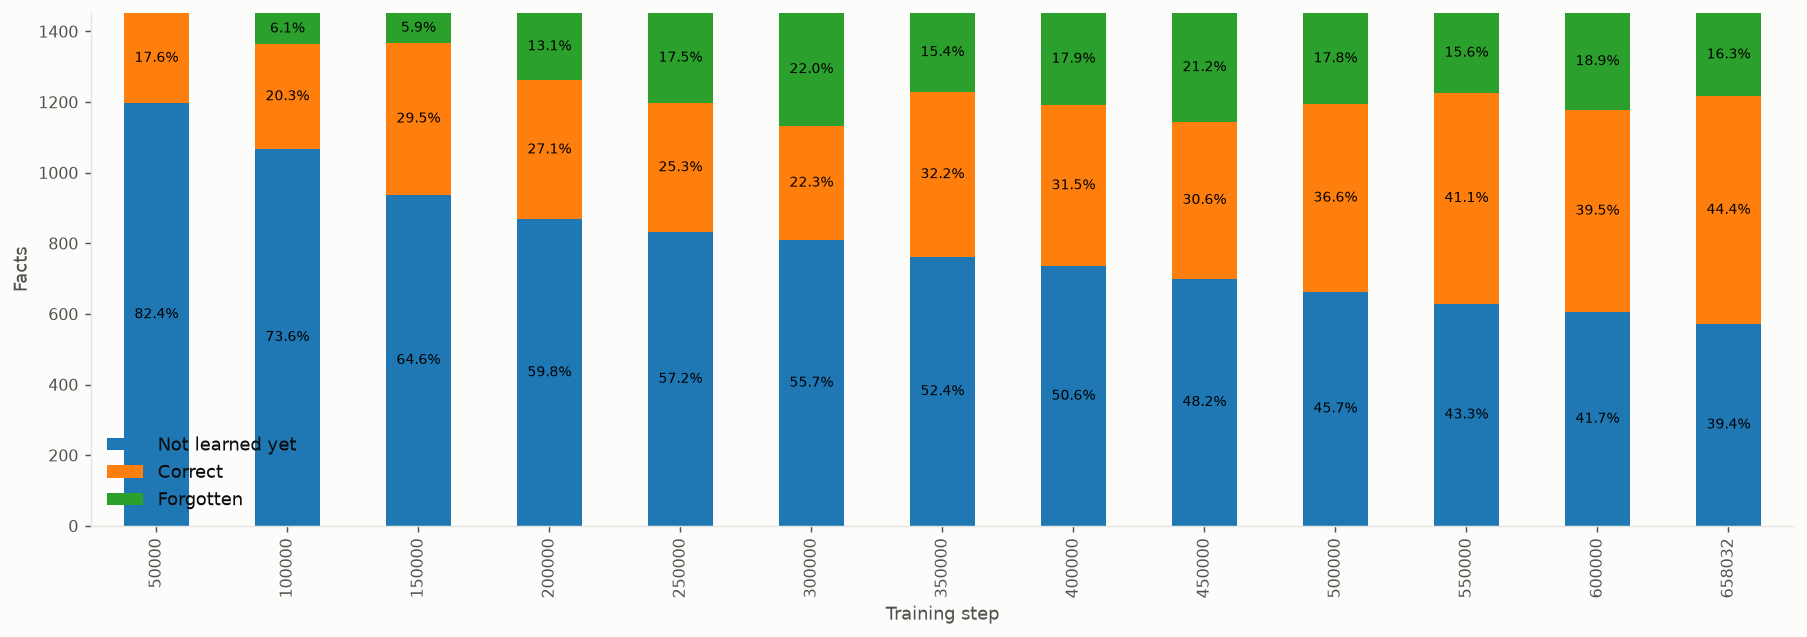

In [23]:
import pandas as pd

counts = []

for t in range(arr.shape[1]):
    current = arr[:, t]
    seen_true = arr[:, :t+1].any(axis=1)

    counts.append({
        "Not learned yet": (~seen_true).sum(),
        "Correct": current.sum(),
        "Forgotten": ((~current) & seen_true).sum()
    })

counts = pd.DataFrame(counts, index=steps)

ax = counts.plot(kind="bar", stacked=True, figsize=(14,5))

# Add percentages
totals = counts.sum(axis=1)

for i, (_, row) in enumerate(counts.iterrows()):
    bottom = 0
    for value in row:
        if value == 0:
            continue
        pct = 100 * value / totals.iloc[i]
        if pct >= 3:
            ax.text(
                i,
                bottom + value / 2,
                f"{pct:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
                color="black",
            )
        bottom += value

plt.ylabel("Facts")
plt.xlabel("Training step")
plt.tight_layout()
plt.show()

In [47]:
# NOTE: an earlier version of this cell added a "Not seen yet" state derived from
# a chunk-id -> step conversion (chunk_id / 15.94). That was WRONG: the model is
# 6 epochs (109672 steps x 6 = 658032), so the within-epoch rate is ~95.7 chunks/
# step and every chunk recurs once per epoch. The correct mapping is the repo's
# schedule.build_chunk_to_steps() (from real batch_indices), not a linear guess.
# Reverted to the original 3-state flow, which never depended on that mapping.
# For a "seen"/interference-aware analysis see forgetting_vs_training_order.ipynb.
arr = learned[steps].to_numpy(dtype=bool)

# Assign a state to every fact at every checkpoint
# 0 = Never learned
# 1 = Correct
# 2 = Forgotten
states = np.zeros_like(arr, dtype=int)

for t in range(arr.shape[1]):
    current = arr[:, t]
    seen_true = arr[:, :t+1].any(axis=1)

    states[:, t] = np.where(
        current,
        1,                                  # Correct
        np.where(seen_true, 2, 0)           # Forgotten or Never learned
    )

state_names = ["Not learned yet", "Correct", "Forgotten"]

# Create node labels

node_index = {}

idx = 0
labels = []

for t, step in enumerate(steps):
    for s, name in enumerate(state_names):
        labels.append(f"{str(step)}<br>{name}")
        node_index[(t, s)] = idx
        idx += 1

# Build links
sources = []
targets = []
values = []

for t in range(len(steps)-1):
    for s1 in range(3):
        for s2 in range(3):
            n = np.sum((states[:, t] == s1) & (states[:, t+1] == s2))
            if n > 0:
                sources.append(node_index[(t, s1)])
                targets.append(node_index[(t+1, s2)])
                values.append(int(n))

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(
        pad=18,
        thickness=18,
        line=dict(color="black", width=0.5),
        label=labels,
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
    )
))

fig.update_layout(
    title="Learning Dynamics Across Training",
    font_size=10,
    width=1600,
    height=700,
)

fig.show()

## Fact properties: what gets learned, and why

The trajectory tells us *when* each fact is learned or forgotten. The PopQA
metadata (`prop`, and the training-data frequency counts) lets us ask *what kind*
of facts are learnable and *why*:

1. **Outcome by relation type** — which `prop`s the model reliably learns and keeps.
2. **Frequency vs. outcome** — learned/retained facts appear far more often in the
   training data (subject mentions, answer mentions, and especially subject–answer
   co-occurrences).
3. **Per-relation summary** — co-occurrence frequency largely explains why some
   relations are easy (`capital`, `sport`) and others nearly impossible
   (`composer`, `mother`).

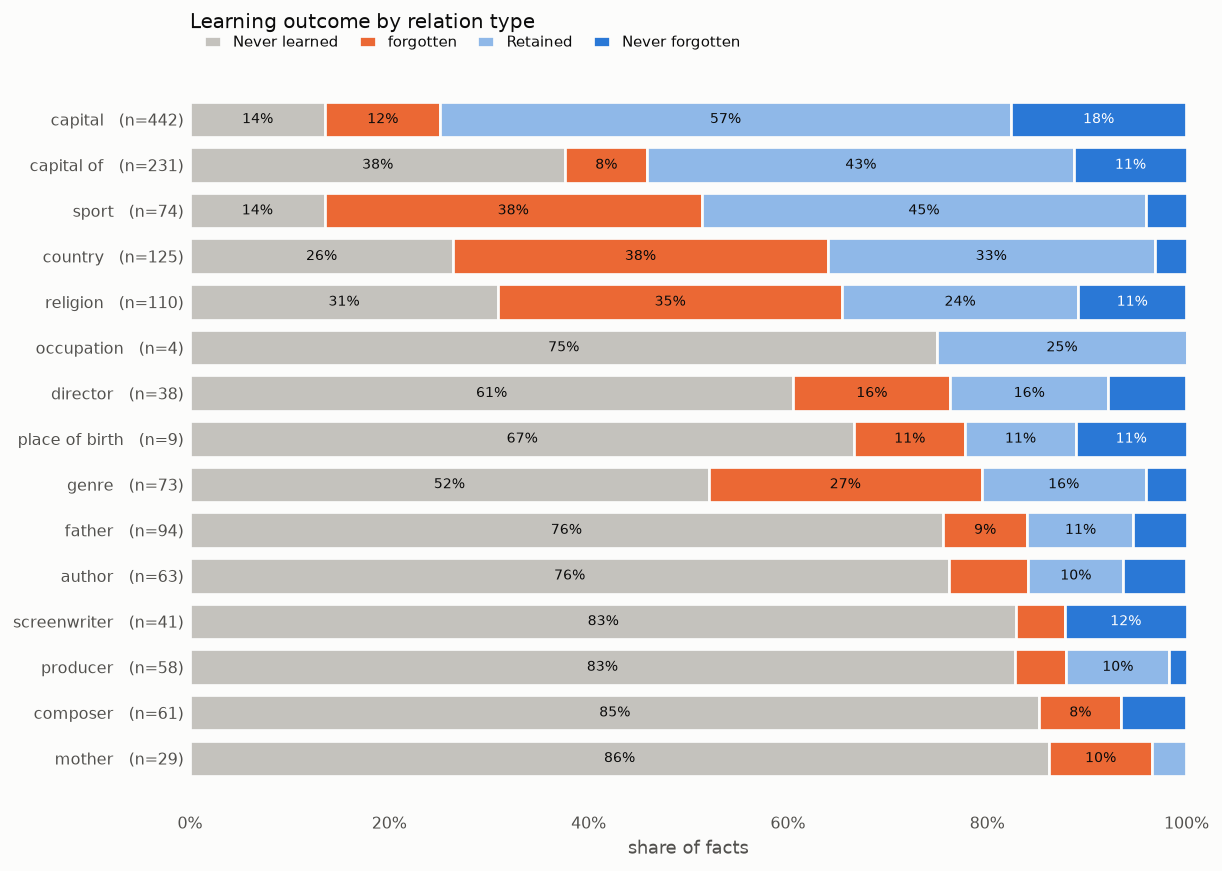

In [27]:
# --- shared style for the fact-property plots ---
# Ordinal outcome ramp: worst -> best. Grey = never touched, orange = learned
# then lost, light blue = retained, dark blue = learned and never lost.
CAT_ORDER = ["Never learned", "forgotten", "Retained", "Never forgotten"]
CAT_COLOR = {
    "Never learned":  "#c4c2bd",
    "forgotten":      "#eb6834",
    "Retained":       "#8fb8e8",
    "Never forgotten": "#2a78d6",
}

# Plot 1 — Learning outcome by relation type (`prop`).
ct = pd.crosstab(df["prop"], df["category"]).reindex(columns=CAT_ORDER, fill_value=0)
n = ct.sum(axis=1)
share = ct.div(n, axis=0)
success = share["Retained"] + share["Never forgotten"]
o = success.sort_values().index
share, n = share.loc[o], n.loc[o]

fig, ax = plt.subplots(figsize=(9.5, 6.8))
left = np.zeros(len(share))
ypos = np.arange(len(share))
for cat in CAT_ORDER:
    vals = share[cat].to_numpy()
    ax.barh(ypos, vals, left=left, color=CAT_COLOR[cat], edgecolor=SURF,
            linewidth=1.5, height=0.78, label=cat)
    txtcol = "white" if cat == "Never forgotten" else INK
    for i, v in enumerate(vals):
        if v >= 0.08:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center",
                    fontsize=8, color=txtcol)
    left += vals

ax.set_yticks(ypos, [f"{p}   (n={n[p]})" for p in share.index], fontsize=9)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("share of facts")
ax.set_title("Learning outcome by relation type", loc="left", pad=22)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.005), ncol=4,
          handlelength=1.1, fontsize=8.5, columnspacing=1.3)
fig.tight_layout()

C:\Users\rotem\AppData\Local\Temp\ipykernel_10288\129370196.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.6,
C:\Users\rotem\AppData\Local\Temp\ipykernel_10288\129370196.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.6,
C:\Users\rotem\AppData\Local\Temp\ipykernel_10288\129370196.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.6,


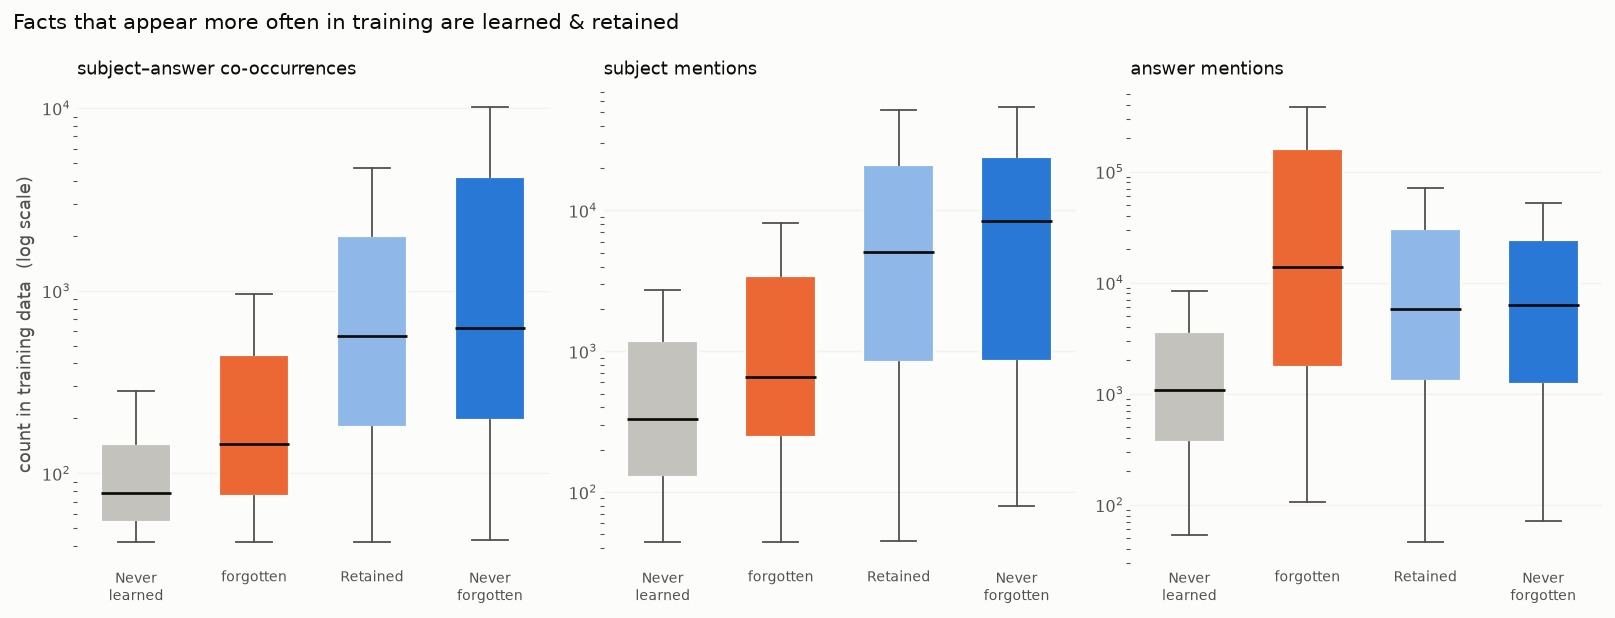

In [28]:
# Plot 2 — How fact frequency in the training data relates to outcome.
# Learned/retained facts co-occur far more often than never-learned ones.
FEATS = [
    ("num_shared_chunks", "subject–answer co-occurrences"),
    ("subject_num_chunks", "subject mentions"),
    ("answer_num_chunks", "answer mentions"),
]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.8))
for ax, (col, label) in zip(axes, FEATS):
    data = [df.loc[df["category"] == c, col].dropna().clip(lower=1).to_numpy()
            for c in CAT_ORDER]
    bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.6,
                    showfliers=False, medianprops=dict(color=INK, lw=1.5),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, c in zip(bp["boxes"], CAT_ORDER):
        patch.set_facecolor(CAT_COLOR[c])
        patch.set_edgecolor(SURF)
        patch.set_linewidth(1.2)
    ax.set_yscale("log")
    ax.set_xticks(range(1, len(CAT_ORDER) + 1),
                  [c.replace(" ", "\n") for c in CAT_ORDER], fontsize=8)
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

axes[0].set_ylabel("count in training data  (log scale)")
fig.suptitle("Facts that appear more often in training are learned & retained",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

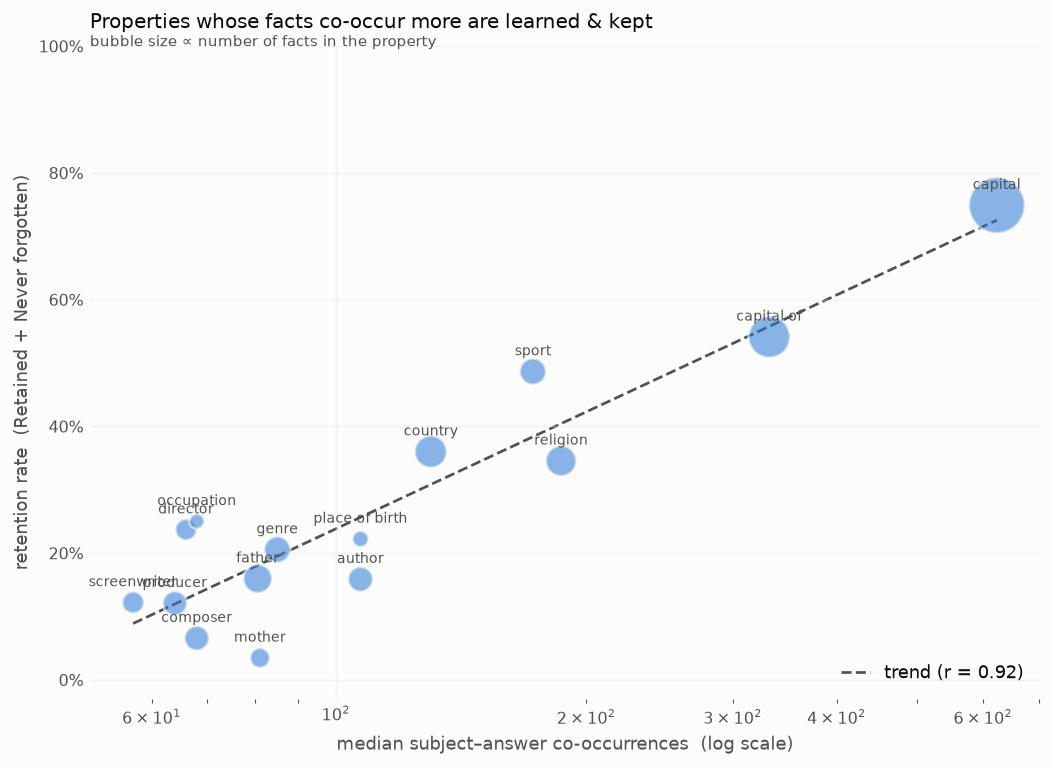

In [46]:
# Plot 3 — Does fact frequency explain per-relation learnability?
# Each relation type: median subject-answer co-occurrence vs. its success rate.
g = df.groupby("prop")
med_shared = g["num_shared_chunks"].median()
success = df.assign(win=df["category"].isin(["Retained", "Never forgotten"])) \
            .groupby("prop")["win"].mean()
nprop = g.size()

x = med_shared.clip(lower=1)
y = success

# fit trend in log-x space
lx = np.log10(x)
b, a = np.polyfit(lx, y, 1)
xs = np.linspace(lx.min(), lx.max(), 50)

fig, ax = plt.subplots(figsize=(8.2, 6))
ax.plot(10**xs, a + b * xs, color=INK2, lw=1.5, ls="--", zorder=1,
        label=f"trend (r = {np.corrcoef(lx, y)[0,1]:.2f})")
ax.scatter(x, y, s=(nprop / nprop.max() * 900) + 60, color=BLUE, alpha=0.55,
           edgecolor=SURF, linewidth=1.5, zorder=2)

for p in x.index:
    ax.annotate(p, (x[p], y[p]), fontsize=8, color=INK2,
                xytext=(0, 9), textcoords="offset points", ha="center")

ax.set_xscale("log")
ax.set_ylim(-0.03, 1.0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("median subject–answer co-occurrences  (log scale)")
ax.set_ylabel("retention rate  (Retained + Never forgotten)")
ax.set_title("Properties whose facts co-occur more are learned & kept",
             loc="left", pad=10)
ax.grid(axis="both", alpha=0.4)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="lower right", handlelength=1.6)
ax.text(0.0, 1, "bubble size ∝ number of facts in the property",
        transform=ax.transAxes, fontsize=8.5, color=INK2)
fig.tight_layout()

## Forgetting events: how much do learned facts wobble?

A *forgetting event* is a checkpoint-to-checkpoint flip from correct → incorrect.
Restricting to the 880 facts that were ever learned:

1. **Distribution × outcome** — most learned facts forget exactly once; and the more
   a fact is forgotten, the more likely it is to end up permanently lost.
2. **Volatility by relation type** — `sport` and `country` facts wobble most;
   `capital`-family facts are comparatively stable.
3. **Timing confound** — raw forgetting counts fall the later a fact is first
   learned, but that is mostly because late learners have fewer remaining
   checkpoints. The per-opportunity *rate* is much flatter.

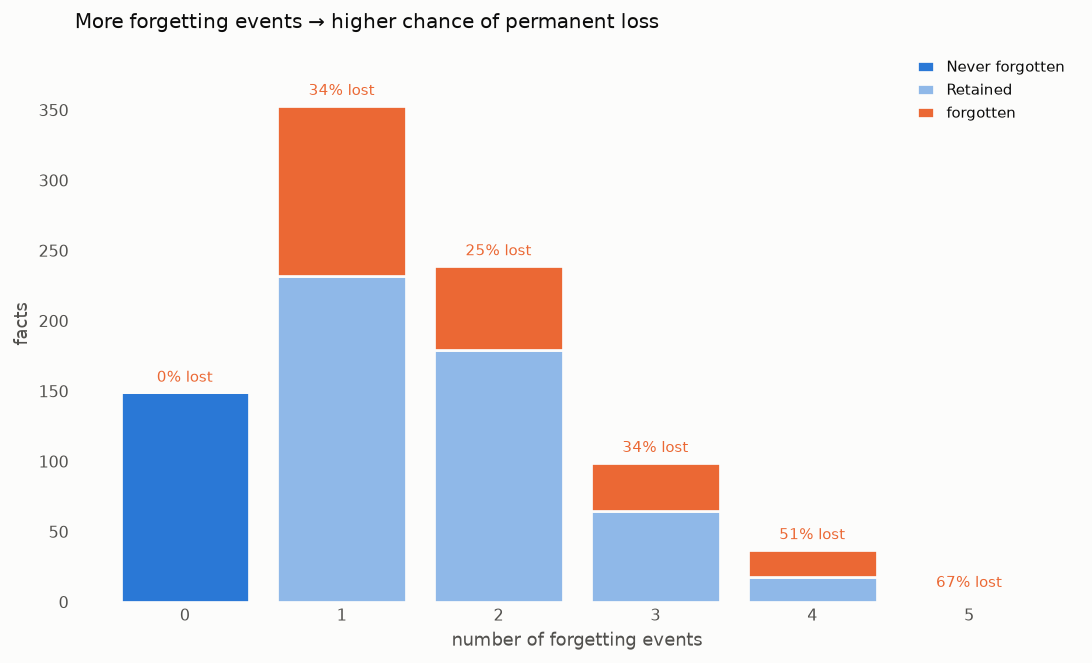

In [30]:
# Forgetting plot 1 — distribution of forgetting events, split by final outcome.
# 0 events == "Never forgotten" by definition. Among facts that wobble, more
# forgetting events => a higher chance the fact is lost by the end of training.
L = df[df["ever_learned"]]
OUT_ORDER = ["Never forgotten", "Retained", "forgotten"]
ct = pd.crosstab(L["forgetting_events"], L["category"]).reindex(columns=OUT_ORDER, fill_value=0)
fe = ct.index.to_numpy()
tot = ct.sum(axis=1).to_numpy()
pct_lost = (ct["forgotten"] / ct.sum(axis=1)).to_numpy()

fig, ax = plt.subplots(figsize=(8.5, 5.2))
bottom = np.zeros(len(ct))
for cat in OUT_ORDER:
    ax.bar(fe, ct[cat], bottom=bottom, color=CAT_COLOR[cat], edgecolor=SURF,
           linewidth=1.5, width=0.82, label=cat)
    bottom += ct[cat].to_numpy()
for i, x in enumerate(fe):
    ax.text(x, tot[i] + 5, f"{pct_lost[i]:.0%} lost", ha="center", va="bottom",
            fontsize=8.5, color=ORANGE)

ax.set_ylim(0, tot.max() * 1.12)
ax.set_xticks(fe)
ax.set_xlabel("number of forgetting events")
ax.set_ylabel("facts")
ax.set_title("More forgetting events → higher chance of permanent loss",
             loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="upper right", handlelength=1.1, fontsize=8.5)
fig.tight_layout()

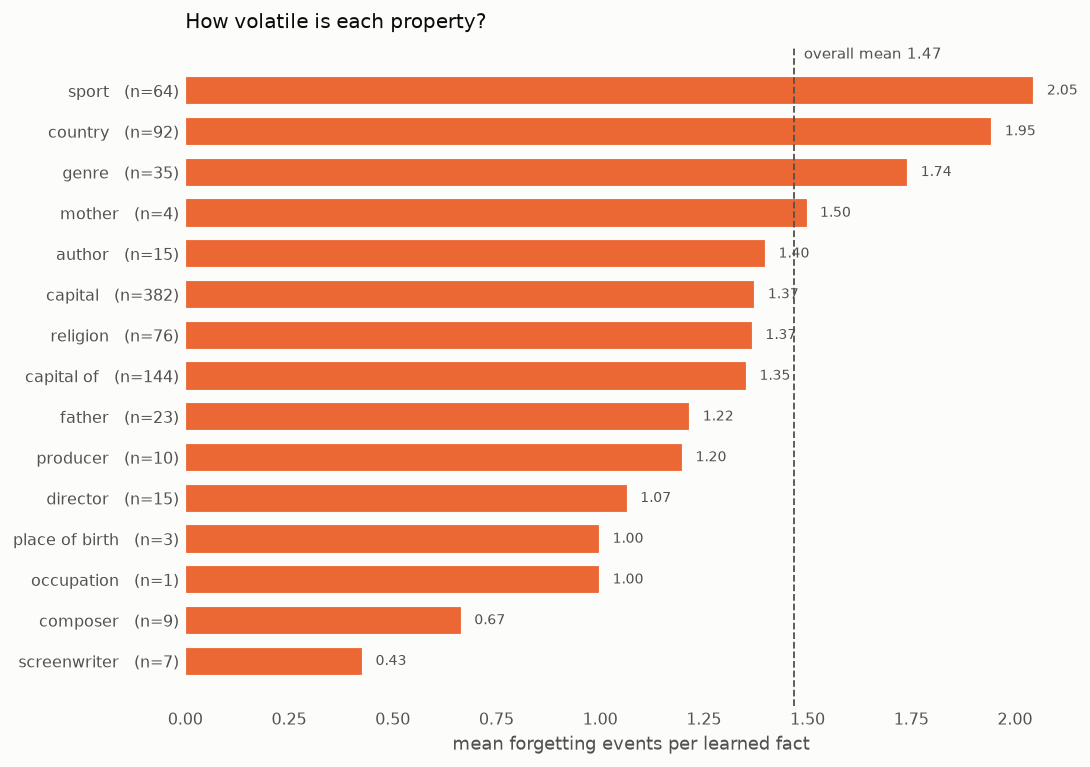

In [45]:
# Forgetting plot 2 — which relation types are most volatile (learned facts only).
L = df[df["ever_learned"]]
byp = L.groupby("prop")["forgetting_events"].agg(["mean", "count"]).sort_values("mean")
overall = L["forgetting_events"].mean()

fig, ax = plt.subplots(figsize=(8.5, 6))
ypos = np.arange(len(byp))
ax.barh(ypos, byp["mean"], color=ORANGE, edgecolor=SURF, linewidth=1.2, height=0.72)
for i, m in enumerate(byp["mean"]):
    ax.text(m + 0.03, i, f"{m:.2f}", va="center", fontsize=8, color=INK2)
ax.axvline(overall, color=INK2, ls="--", lw=1)
ax.text(overall, len(byp) - 0.3, f"  overall mean {overall:.2f}",
        color=INK2, fontsize=8.5, va="bottom")

ax.set_yticks(ypos, [f"{p}   (n={c})" for p, c in zip(byp.index, byp['count'])], fontsize=9)
ax.set_xlabel("mean forgetting events per learned fact")
ax.set_title("How volatile is each property?", loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

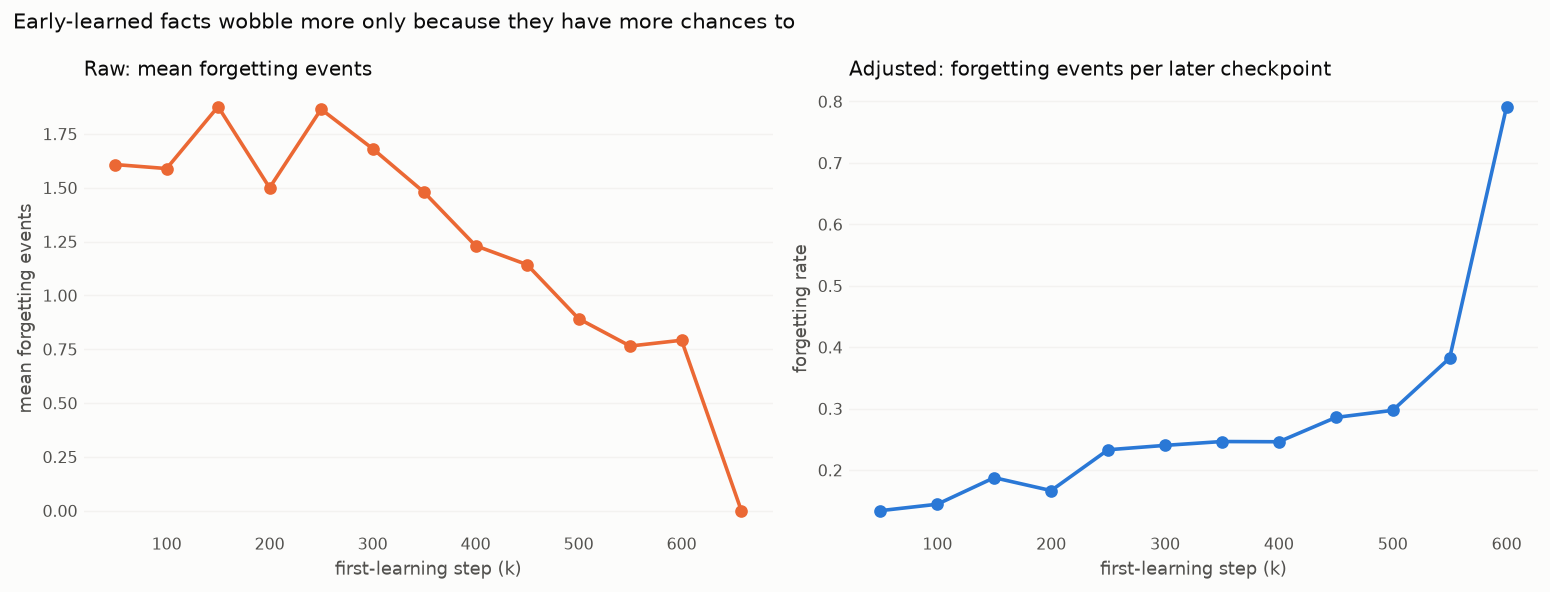

In [32]:
# Forgetting plot 3 — the count is confounded by WHEN a fact is first learned.
# A fact learned early has many later checkpoints at which it can wobble; a fact
# learned late has few. Raw counts fall with a later first-learning step, but the
# per-opportunity forgetting *rate* is much flatter.
L = df[df["ever_learned"]].copy()
step_list = [int(c) for c in df.columns[1:14]]
pos = {s: i for i, s in enumerate(step_list)}
L["fidx"] = L["first_learning_step"].astype(int).map(pos)
L["opportunities"] = (len(step_list) - 1) - L["fidx"]          # checkpoints after first learn
L["forget_rate"] = L["forgetting_events"] / L["opportunities"].replace(0, np.nan)

raw = L.groupby("first_learning_step")["forgetting_events"].mean()
rate = L.dropna(subset=["forget_rate"]).groupby("first_learning_step")["forget_rate"].mean()
xr = [s / 1000 for s in raw.index]
xt = [s / 1000 for s in rate.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.plot(xr, raw.values, marker="o", ms=6, color=ORANGE, lw=2)
ax1.set_title("Raw: mean forgetting events", loc="left")
ax1.set_ylabel("mean forgetting events")
ax2.plot(xt, rate.values, marker="o", ms=6, color=BLUE, lw=2)
ax2.set_title("Adjusted: forgetting events per later checkpoint", loc="left")
ax2.set_ylabel("forgetting rate")
for ax in (ax1, ax2):
    ax.set_xlabel("first-learning step (k)")
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Early-learned facts wobble more only because they have more chances to",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## Learning frequency vs. forgetting frequency (the paper's phenomenon)

The paper reports that **the more frequently a fact is learned, the more frequently
it is also forgotten**. We reproduce this per relation type: on the x-axis the
**learning frequency** (mean `num_shared_chunks` — subject–answer co-occurrences in
training, the driver of acquisition), on the y-axis the **forgetting frequency**
(mean number of forgetting events — correct→incorrect flips — per learned fact).

Note this is the *count* of forgetting events, not the per-opportunity rate: the
same high-frequency facts that are acquired early keep wobbling, so they rack up
more forgetting events over training. (The per-opportunity *rate* tells the
opposite, timing-adjusted story — see the raw-vs-adjusted panel above.)

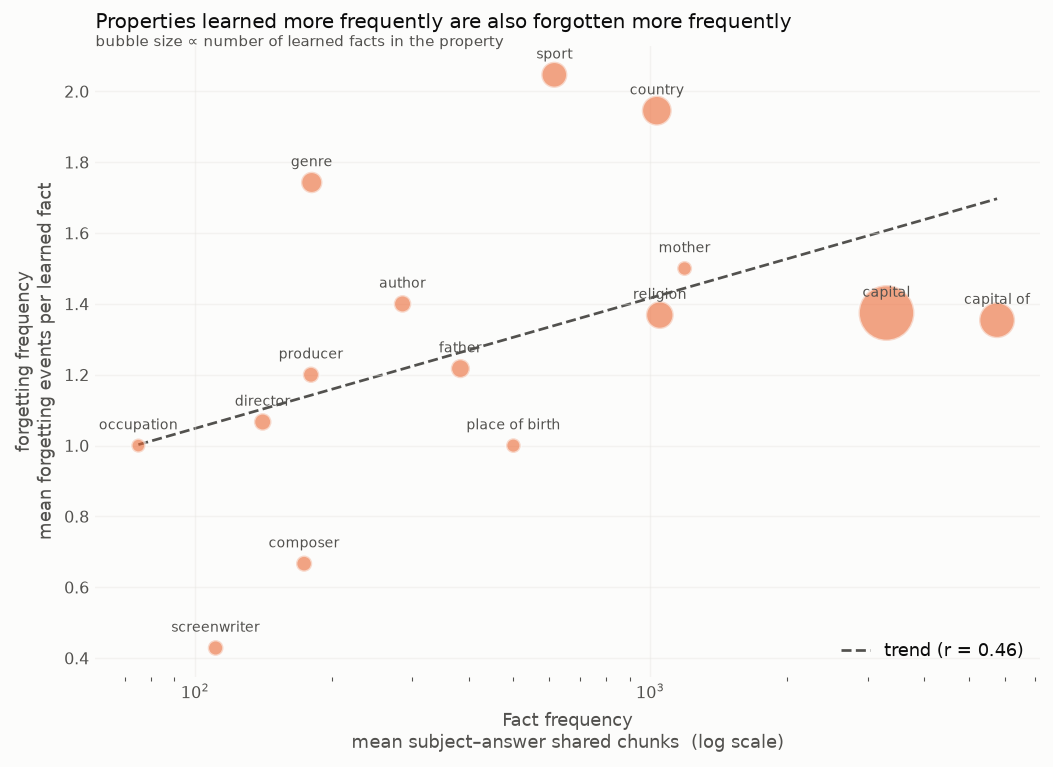

In [44]:
# Learning frequency (mean shared chunks) vs. forgetting frequency (mean forgetting
# events), per relation type. Reproduces the paper's phenomenon: relations whose
# facts co-occur more in training are learned more -- and also forgotten more often.
L = df[df["ever_learned"]].copy()

g = L.groupby("prop")
fact_freq  = g["num_shared_chunks"].mean()      # fact frequency (training co-occurrence)
forget_freq = g["forgetting_events"].mean()      # forgetting frequency (# of correct->incorrect flips)
nprop = g.size()

x = fact_freq.clip(lower=1)
y = forget_freq.reindex(x.index)

# fit trend in log-x space
lx = np.log10(x)
b, a = np.polyfit(lx, y, 1)
xs = np.linspace(lx.min(), lx.max(), 50)
r = np.corrcoef(lx, y)[0, 1]

fig, ax = plt.subplots(figsize=(8.2, 6))
ax.plot(10**xs, a + b * xs, color=INK2, lw=1.5, ls="--", zorder=1,
        label=f"trend (r = {r:.2f})")
ax.scatter(x, y, s=(nprop / nprop.max() * 900) + 60, color=ORANGE, alpha=0.6,
           edgecolor=SURF, linewidth=1.5, zorder=2)

for p in x.index:
    ax.annotate(p, (x[p], y[p]), fontsize=8, color=INK2,
                xytext=(0, 9), textcoords="offset points", ha="center")

ax.set_xscale("log")
ax.set_xlabel("Fact frequency\nmean subject–answer shared chunks  (log scale)")
ax.set_ylabel("forgetting frequency\nmean forgetting events per learned fact")
ax.set_title("Properties learned more frequently are also forgotten more frequently",
             loc="left", pad=10)
ax.grid(axis="both", alpha=0.4)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="lower right", handlelength=1.6)
ax.text(0.0, 1, "bubble size ∝ number of learned facts in the property",
        transform=ax.transAxes, fontsize=8.5, color=INK2)
fig.tight_layout()